# Index Construction and Smart Beta: Price-Weighted, Capitalisation-Weighted, Equal-Weighted and Fundamental Indexes of the S&P 500 from Public Data, Turnover and Rebalancing Costs, and a Machine-Learning Tilt

An index is a portfolio rule. The CFA curriculum's equity readings define the classic weighting schemes:

- **Price-weighted** (the Dow): each stock weighted by its price, so a USD 500 stock counts ten times a USD 50 stock regardless of size.
- **Capitalisation-weighted** (the S&P 500): weight = price × shares, self-rebalancing, low turnover, but it puts more money into whatever has gone up.
- **Equal-weighted:** every stock the same weight, rebalanced back each period; it tilts towards smaller companies and sells winners.
- **Fundamentally weighted** (Arnott, Hsu and Moore, 2005): weights from sales, cash flow, book value and dividends, which breaks the link between weight and price.

"Smart beta" products are these rules packaged as funds. This notebook builds all four from public data for the stocks in today's S&P 500, from 2011 to 2026, measures their returns, risk, turnover and rebalancing costs, and adds a fifth: a capitalisation-weighted index **tilted by a LightGBM forecast** of each stock's next-year return, trained only on past data.

**Data.** Yahoo Finance (monthly adjusted prices of today's S&P 500 members and the S&P 500 ETF, 2010–2026); iShares Core S&P 500 ETF holdings (members); SEC XBRL frames API (shares outstanding, revenue, operating cash flow, equity, dividends, 2010–2025).

**Methods.** Price, capitalisation, equal and fundamental weighting, annual rebalancing, turnover and transaction costs, tracking error and information ratio, Sharpe ratios, LightGBM cross-sectional return forecasts and weight tilts.

**Key output.** Return, volatility, Sharpe ratio, turnover and tracking error of each index rule; how much of the difference survives costs; and whether an ML tilt adds value out of sample.

## 1. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import io
import lightgbm as lgb
import yfinance as yf

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2026
SEC_HEADERS = {"User-Agent": os.getenv("SEC_USER_AGENT", "").strip()}
if not SEC_HEADERS["User-Agent"]:
    raise RuntimeError(
        "SEC_USER_AGENT missing in .env (the SEC asks automated clients to"
        " identify themselves)."
    )
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}
IVV_URL = "https://www.ishares.com/us/products/239726/fund/latest-holdings.csv"
FIRST_CY, LAST_CY = 2009, 2025
CONCEPTS = {
    "rev": (
        "us-gaap",
        [
            "Revenues",
            "RevenueFromContractWithCustomerExcludingAssessedTax",
            "SalesRevenueNet",
        ],
        "USD",
        "",
    ),
    "cfo": (
        "us-gaap",
        ["NetCashProvidedByUsedInOperatingActivities"],
        "USD",
        "",
    ),
    "equity": ("us-gaap", ["StockholdersEquity"], "USD", "Q4I"),
    "div": (
        "us-gaap",
        ["PaymentsOfDividends", "PaymentsOfDividendsCommonStock"],
        "USD",
        "",
    ),
    "shares": ("dei", ["EntityCommonStockSharesOutstanding"], "shares", "Q4I"),
}
# Fallbacks for share counts (cover-page counts are missing for many filers and
# for multi-class companies)
SHARE_CONCEPTS = {
    "shares_q1": (
        "dei",
        ["EntityCommonStockSharesOutstanding"],
        "shares",
        "Q1I",
    ),
    "shares_bs": (
        "us-gaap",
        ["CommonStockSharesOutstanding"],
        "shares",
        "Q4I",
    ),
    "shares_dil": (
        "us-gaap",
        ["WeightedAverageNumberOfDilutedSharesOutstanding"],
        "shares",
        "",
    ),
}
# rebalance at the end of May, after fiscal-year 10-Ks are public
REBAL_MONTH = 5
COST_BPS = 10  # one-way trading cost
# ML tilt: weight × (1 + TILT × standardised predicted rank)
TILT = 0.5

print(
    f"lightgbm {lgb.__version__} · yfinance {yf.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

lightgbm 4.7.0 · yfinance 1.7.0 · run on 2026-11-12


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 2. Data

Today's S&P 500 members (a survivorship-biased universe, discussed at the end), their monthly prices, and from the XBRL frames their year-end shares outstanding and fundamentals. Yahoo's closing prices are restated for later stock splits while SEC share counts are not, so both are put back on the basis of the rebalance date using Yahoo's split history; without this step, every company that later split (Apple, Nvidia, Amazon, Alphabet, Tesla, …) would get a fraction of its true weight. Each May, the index weights are set from the latest prices and the previous fiscal year's data and held for twelve months (cap-weighted and price-weighted portfolios drift with prices between rebalances, as real indexes do).

In [3]:
def sec_get(url):
    for attempt in range(4):
        r = requests.get(url, headers=SEC_HEADERS, timeout=300)
        if r.status_code == 200:
            return r
        if r.status_code == 404:
            return None
        time.sleep(2 + 3 * attempt)
    r.raise_for_status()


def fetch_ivv():
    lines = requests.get(
        IVV_URL, headers=BROWSER_HEADERS, timeout=60
    ).text.splitlines()
    header = next(i for i, l in enumerate(lines) if l.startswith("Ticker"))
    t = pd.read_csv(
        io.StringIO("\n".join(lines[header:])), dtype=str, on_bad_lines="skip"
    )
    return t[t["Asset Class"] == "Equity"][["Ticker", "Name", "Sector"]]


def fetch_frames(concepts=CONCEPTS):
    out = []
    for item, (tax, tags, unit, sfx) in concepts.items():
        for rank, tag in enumerate(tags):
            for cy in range(FIRST_CY, LAST_CY + 1):
                r = sec_get(
                    f"https://data.sec.gov/api/xbrl/frames/{tax}/{tag}/{unit}/CY{cy}{sfx}.json"
                )
                if r is None:
                    continue
                out.append(
                    pd.DataFrame(r.json()["data"])[["cik", "val"]].assign(
                        item=item, cy=cy, rank=rank
                    )
                )
                time.sleep(0.12)
    return pd.concat(out, ignore_index=True)


IVV = cached("ivv_holdings", fetch_ivv, max_age_hours=24 * 30)
tick = pd.DataFrame(
    sec_get("https://www.sec.gov/files/company_tickers.json").json()
).T
cik_of = {
    t.replace(".", "-"): int(c) for t, c in zip(tick.ticker, tick.cik_str)
}
UNI = IVV.copy()
UNI["yt"] = UNI.Ticker.str.replace(".", "-", regex=False)
UNI["cik"] = UNI.yt.map(cik_of)
UNI = UNI.dropna(subset=["cik"]).drop_duplicates("cik").astype({"cik": int})
PX = cached(
    "yahoo_monthly_sp500_index",
    lambda: yf.download(
        UNI.yt.tolist() + ["SPY"],
        start="2010-01-01",
        interval="1mo",
        auto_adjust=True,
        progress=False,
        threads=True,
    )["Close"],
    max_age_hours=24 * 14,
)
RAWPX = cached(
    "yahoo_monthly_sp500_unadjusted",
    lambda: yf.download(
        UNI.yt.tolist(),
        start="2010-01-01",
        interval="1mo",
        auto_adjust=False,
        progress=False,
        threads=True,
    )["Close"],
    max_age_hours=24 * 14,
)
SPL = cached(
    "yahoo_monthly_sp500_splits",
    lambda: yf.download(
        UNI.yt.tolist(),
        start="2010-01-01",
        interval="1mo",
        actions=True,
        auto_adjust=False,
        progress=False,
        threads=True,
    )["Stock Splits"],
    max_age_hours=24 * 14,
)
for X in (PX, RAWPX, SPL):
    X.index = pd.to_datetime(X.index)
# Yahoo's "Close" is split-adjusted, while XBRL share counts are historical.
# FUT_SPLIT[t] at month m = product of all splits
# after m, used to put historical share counts and split-adjusted prices on the
# same basis.
SPL = SPL.reindex(PX.index).replace(0, 1.0).fillna(1.0)
FUT_SPLIT = SPL[::-1].cumprod()[::-1].shift(-1).fillna(1.0)
FR = cached(
    "sec_frames_index_construction", fetch_frames, max_age_hours=24 * 14
)
FR = FR.sort_values("rank").drop_duplicates(["cik", "item", "cy"])
FS = cached(
    "sec_frames_share_counts",
    lambda: fetch_frames(SHARE_CONCEPTS),
    max_age_hours=24 * 14,
)
# a count dated early in year Y+1 describes fiscal Y
FS.loc[FS.item == "shares_q1", "cy"] -= 1
FR = pd.concat(
    [FR, FS.drop_duplicates(["cik", "item", "cy"])], ignore_index=True
)
F = (
    FR[FR.cik.isin(UNI.cik)]
    .pivot_table(index=["cik", "cy"], columns="item", values="val")
    .reset_index()
)
# Share count: the cover-page counts (never restated), year end or early next
# year; the balance-sheet count and the diluted
# weighted average only as fallbacks, because frames take them from the latest
# filing, which restates them for later splits
F["shares"] = (
    F[["shares", "shares_q1"]]
    .median(axis=1)
    .combine_first(F.shares_bs)
    .combine_first(F.shares_dil)
)
RET = PX.pct_change(fill_method=None)
print(
    f"{len(UNI)} members mapped to CIKs; prices {PX.index.min():%Y-%m} →"
    f" {PX.index.max():%Y-%m}; fundamentals for {F.cik.nunique()} companies"
)

498 members mapped to CIKs; prices 2010-01 → 2026-11; fundamentals for 497 companies


## 3. Five indexes

At each rebalance (end of May, year *Y*, using fiscal *Y* − 1 data):

| Index | Weight of stock *i* |
|---|---|
| Price-weighted | unadjusted price |
| Cap-weighted | price × shares outstanding |
| Equal-weighted | 1 / N |
| Fundamental | average of the stock's shares of total sales, operating cash flow, book equity and dividends (RAFI-style) |
| ML-tilted | cap weight × (1 + 0.5 × standardised predicted return rank), renormalised |

The ML model is LightGBM trained, at each rebalance, on all earlier rebalances: features are the trailing 12-1 month momentum, 1-month reversal, trailing volatility, size, sales-to-price, cash-flow-to-price, book-to-price and dividend yield; the target is the next twelve months' return rank within the universe.

In [4]:
UNI = UNI.set_index("yt")
cikmap = UNI.cik.to_dict()
FI = F.set_index(["cik", "cy"])
reb = [d for d in PX.index if d.month == REBAL_MONTH and d.year >= 2011]
rows = []
for d in reb:
    fy = d.year - 1
    i = PX.index.get_loc(d)
    if i + 1 >= len(PX):
        break
    for t in UNI.index:
        if t not in PX or not np.isfinite(PX[t].iloc[i]):
            continue
        k = (cikmap[t], fy)
        f = FI.loc[k] if k in FI.index else None
        px, raw = PX[t].iloc[i], RAWPX[t].iloc[i] if t in RAWPX else np.nan
        fs = FUT_SPLIT[t] if t in FUT_SPLIT else None
        k_dec = PX.index.get_indexer(
            [pd.Timestamp(fy, 12, 1)], method="nearest"
        )[0]
        # price actually traded at the rebalance
        raw = raw * fs.iloc[i] if fs is not None else raw
        # shares restated to that date
        sh_adj = (
            (f["shares"] * fs.iloc[k_dec] / fs.iloc[i])
            if (f is not None and fs is not None)
            else np.nan
        )
        hist = RET[t].iloc[max(0, i - 12) : i + 1]
        fwd = (
            PX[t].iloc[min(i + 12, len(PX) - 1)] / px - 1
            if i + 12 < len(PX)
            else np.nan
        )
        rows.append({
            "date": d,
            "ticker": t,
            "price": raw,
            "shares": sh_adj,
            "sh_basis": (
                (f["shares"] * fs.iloc[k_dec])
                if (f is not None and fs is not None)
                else np.nan
            ),
            "rev": f["rev"] if f is not None else np.nan,
            "cfo": f["cfo"] if f is not None else np.nan,
            "equity": f["equity"] if f is not None else np.nan,
            "div": f["div"] if f is not None else np.nan,
            "mom": (
                PX[t].iloc[i - 1] / PX[t].iloc[i - 12] - 1
                if i >= 12
                else np.nan
            ),
            "rev1m": hist.iloc[-1] if len(hist) else np.nan,
            "vol": hist.std() * np.sqrt(12),
            "fwd12": fwd,
        })
S = pd.DataFrame(rows)
# On today's split basis a company's share count moves slowly; a count more
# than 1.5× away from the median of its five neighbouring years is treated as a
# data error (mis-scaled value or split timing) and that company-year is left
# out
S = S.sort_values(["ticker", "date"]).reset_index(drop=True)
med = S.groupby("ticker").sh_basis.transform(
    lambda v: v.rolling(5, center=True, min_periods=3).median()
)
with np.errstate(invalid="ignore", divide="ignore"):
    dev = np.abs(np.log(S.sh_basis / med))
bad = dev > np.log(1.5)
S.loc[bad, "shares"] = np.nan
print(f"{bad.sum()} company-years with an implausible share count dropped")
S["mcap"] = S.price * S.shares
S = S[S.mcap > 0].copy()
for c in ["rev", "cfo", "equity", "div"]:
    S[f"{c}_p"] = (S[c] / S.mcap).clip(-2, 5)
S["size"] = np.log(S.mcap)
print(
    f"{S.date.nunique()} annual rebalances, median"
    f" {S.groupby('date').size().median():.0f} stocks with shares and price"
)

118 company-years with an implausible share count dropped
16 annual rebalances, median 448 stocks with shares and price


In [5]:
FEATS = ["mom", "rev1m", "vol", "size", "rev_p", "cfo_p", "equity_p", "div_p"]
S["rank_fwd"] = S.groupby("date").fwd12.rank(pct=True)
S["pred"] = np.nan
for d in sorted(S.date.unique()):
    tr = S[(S.date <= d - pd.DateOffset(months=12)) & S.rank_fwd.notna()]
    if tr.date.nunique() < 3:
        continue
    m = lgb.LGBMRegressor(
        n_estimators=300,
        learning_rate=0.03,
        num_leaves=15,
        min_child_samples=40,
        verbose=-1,
        random_state=SEED,
    ).fit(tr[FEATS], tr.rank_fwd)
    S.loc[S.date == d, "pred"] = m.predict(S.loc[S.date == d, FEATS])


def weights(g, scheme):
    if scheme == "Price-weighted":
        w = g.price
    elif scheme == "Cap-weighted":
        w = g.mcap
    elif scheme == "Equal-weighted":
        w = pd.Series(1.0, index=g.index)
    elif scheme == "Fundamental":
        parts = [
            (g[c].clip(lower=0) / g[c].clip(lower=0).sum())
            for c in ["rev", "cfo", "equity", "div"]
            if g[c].clip(lower=0).sum() > 0
        ]
        w = sum(p.fillna(0) for p in parts) / len(parts)
    else:
        if g.pred.isna().all():
            w = g.mcap
        else:
            z = (g.pred.rank(pct=True) - 0.5) / 0.289
            w = g.mcap * (1 + TILT * z).clip(lower=0)
    w = w.fillna(0)
    return pd.Series((w / w.sum()).to_numpy(), index=g.ticker.to_numpy())


SCHEMES = [
    "Price-weighted",
    "Cap-weighted",
    "Equal-weighted",
    "Fundamental",
    "ML-tilted",
]
months = PX.index[PX.index > reb[0]]
IDX = {s: [] for s in SCHEMES}
TURN = {s: [] for s in SCHEMES}
prev = {s: None for s in SCHEMES}
for k, d in enumerate([r for r in reb if r in set(S.date)]):
    g = S[S.date == d]
    nxt = [m for m in months if m > d][:12]
    for s in SCHEMES:
        w0 = weights(g, s)
        if prev[s] is not None:
            al = pd.concat([prev[s], w0], axis=1).fillna(0)
            TURN[s].append(0.5 * (al.iloc[:, 0] - al.iloc[:, 1]).abs().sum())
        w = w0.copy()
        for j, m in enumerate(nxt):
            r = RET.loc[m, w.index].fillna(0)
            pr = (w * r).sum()
            cost = (
                (TURN[s][-1] * 2 * COST_BPS / 1e4)
                if (j == 0 and prev[s] is not None)
                else 0.0
            )
            IDX[s].append((m, pr - cost, pr))
            w = w * (1 + r)
            w = w / w.sum()
        # drifted weights before the next rebalance
        prev[s] = w
R = {
    s: pd.DataFrame(v, columns=["date", "net", "gross"]).set_index("date")
    for s, v in IDX.items()
}
spy = RET.SPY.reindex(R["Cap-weighted"].index)

In [6]:
def stats(r, b):
    ex = r - b
    return {
        "annual return": (1 + r).prod() ** (12 / len(r)) - 1,
        "volatility": r.std() * np.sqrt(12),
        "Sharpe (no risk-free)": r.mean() / r.std() * np.sqrt(12),
        "max drawdown": (
            ((1 + r).cumprod() / (1 + r).cumprod().cummax() - 1).min()
        ),
        "tracking error vs SPY": ex.std() * np.sqrt(12),
        "information ratio": (
            ex.mean() / ex.std() * np.sqrt(12) if ex.std() > 0 else np.nan
        ),
    }


PERF = pd.DataFrame({
    s: {
        **stats(R[s].net, spy),
        "annual one-way turnover": np.mean(TURN[s]) if TURN[s] else np.nan,
        "cost drag (bp a year)": (
            (
                (1 + R[s].gross).prod() ** (12 / len(R[s]))
                - (1 + R[s].net).prod() ** (12 / len(R[s]))
            )
            * 1e4
        ),
    }
    for s in SCHEMES
}).T
PERF.loc["S&P 500 ETF (SPY)"] = pd.Series({**stats(spy, spy)})
oos = R["ML-tilted"].index >= S[S.pred.notna()].date.min()
print(
    f"{R['Cap-weighted'].index.min():%Y-%m} →"
    f" {R['Cap-weighted'].index.max():%Y-%m}, net of {COST_BPS} bp one-way"
    f" costs; ML tilt active from {S[S.pred.notna()].date.min():%Y-%m}"
)
display(PERF.round(3))
ml_ex = (R["ML-tilted"].net - R["Cap-weighted"].net)[oos]
ic = (
    S.dropna(subset=["pred", "rank_fwd"])
    .groupby("date")
    .apply(
        lambda g: g.pred.corr(g.rank_fwd, method="spearman"),
        include_groups=False,
    )
)
print(
    f"ML tilt vs cap-weighted, out of sample: excess {ml_ex.mean() * 12:+.2%}"
    f" a year, t = {ml_ex.mean() / ml_ex.std() * np.sqrt(len(ml_ex)):.2f};"
    f" mean rank IC {ic.mean():.3f} ({(ic > 0).sum()} of {len(ic)} years"
    " positive)"
)
ic.round(3).to_frame("rank IC by rebalance").T

2011-06 → 2026-11, net of 10 bp one-way costs; ML tilt active from 2014-05


,annual return,volatility,Sharpe (no risk-free),max drawdown,tracking error vs SPY,information ratio,annual one-way turnover,cost drag (bp a year)
Price-weighted,0.15,0.15,1.06,-0.24,0.04,0.37,0.05,1.01
Cap-weighted,0.15,0.14,1.08,-0.24,0.01,1.42,0.04,0.92
Equal-weighted,0.18,0.15,1.20,-0.23,0.05,0.90,0.12,2.68
Fundamental,0.15,0.14,1.07,-0.24,0.04,0.30,0.13,2.84
ML-tilted,0.16,0.15,1.07,-0.27,0.03,0.78,0.21,4.67
S&P 500 ETF (SPY),0.14,0.14,0.99,-0.24,0.00,NaN,NaN,NaN


ML tilt vs cap-weighted, out of sample: excess +0.93% a year, t = 1.33; mean rank IC 0.040 (8 of 12 years positive)


date,2014-05-01,2015-05-01,2016-05-01,2017-05-01,2018-05-01,2019-05-01,2020-05-01,2021-05-01,2022-05-01,2023-05-01,2024-05-01,2025-05-01
rank IC by rebalance,0.12,-0.03,0.00,0.09,-0.01,0.05,0.22,-0.12,0.11,0.07,-0.05,0.04


## 4. Charts

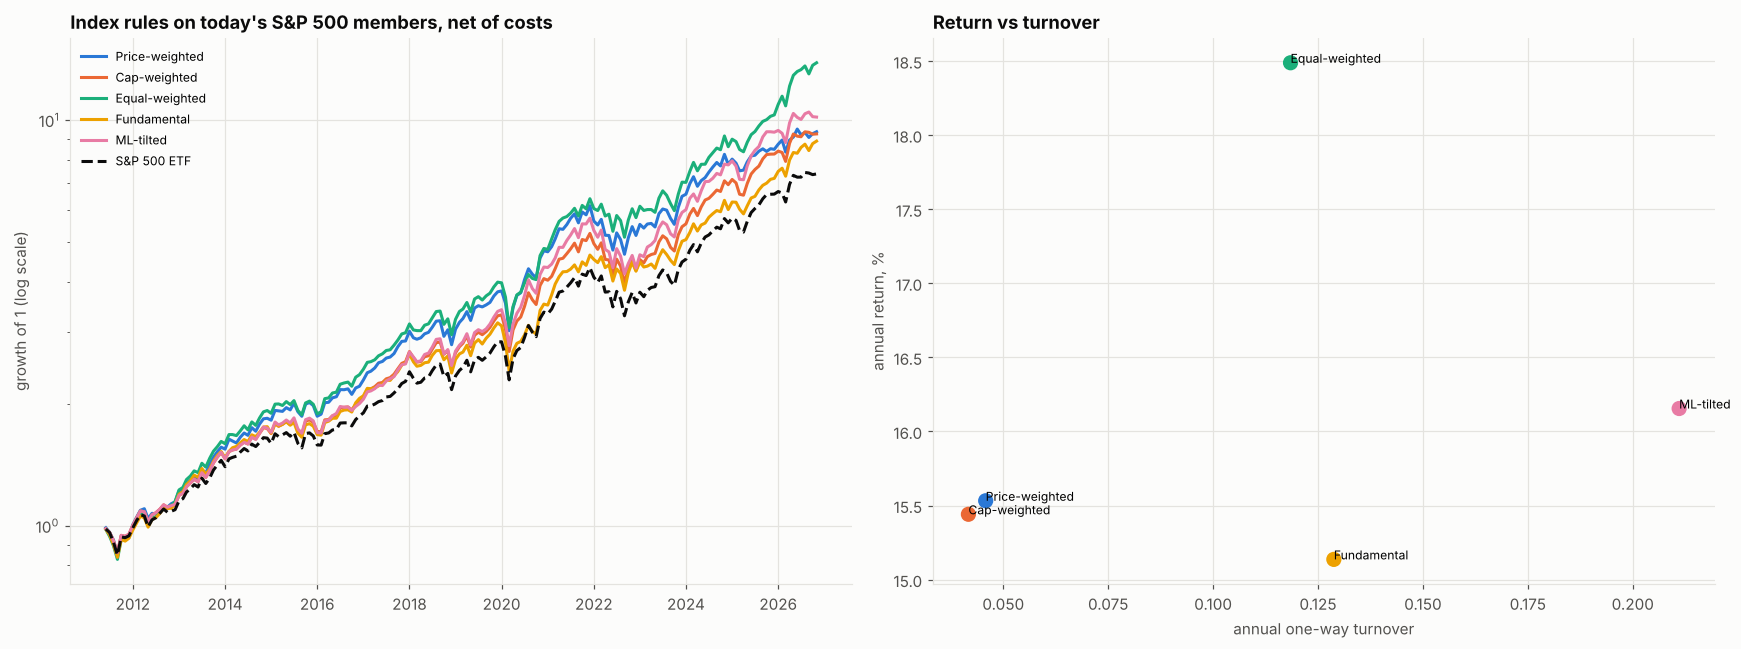

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
a = ax[0]
for i, s in enumerate(SCHEMES):
    a.plot((1 + R[s].net).cumprod(), color=PALETTE[i], label=s)
a.plot((1 + spy).cumprod(), color=INK, ls="--", label="S&P 500 ETF")
a.set_yscale("log")
a.set_ylabel("growth of 1 (log scale)")
a.set_title("Index rules on today's S&P 500 members, net of costs")
a.legend(fontsize=8)
a = ax[1]
a.scatter(
    PERF["annual one-way turnover"],
    PERF["annual return"] * 100,
    s=80,
    color=PALETTE[: len(PERF)],
)
for s, r in PERF.iterrows():
    a.annotate(
        s, (r["annual one-way turnover"], r["annual return"] * 100), fontsize=8
    )
a.set_xlabel("annual one-way turnover")
a.set_ylabel("annual return, %")
a.set_title("Return vs turnover")
fig.tight_layout()
save_fig(fig, "01_index_construction")
plt.show()

In [8]:
dash = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "Rolling 36-month excess return vs SPY (%)",
        "Weight of the 10 largest stocks",
    ),
)
for i, s in enumerate(SCHEMES):
    ex = (R[s].net - spy).rolling(36).mean() * 1200
    dash.add_trace(
        go.Scatter(x=ex.index, y=ex, name=s, line_color=PALETTE[i]), 1, 1
    )
conc = {
    s: [
        weights(S[S.date == d], s).nlargest(10).sum()
        for d in sorted(S.date.unique())
    ]
    for s in SCHEMES
}
for i, s in enumerate(SCHEMES):
    dash.add_trace(
        go.Scatter(
            x=sorted(S.date.unique()),
            y=np.array(conc[s]) * 100,
            name=s,
            line_color=PALETTE[i],
            showlegend=False,
        ),
        1,
        2,
    )
dash.update_layout(
    height=550,
    width=1400,
    template="simple_white",
    title="Index construction and smart beta",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 5. Reading the results and limitations

**The rebuilt cap-weighted index tracks the real one.** From public data alone (today's 498 members, Yahoo prices and SEC share counts), the cap-weighted index has a tracking error of 1.1% a year against the S&P 500 ETF and turnover of 4% a year. This check matters because the raw data do not line up on their own:
- **Splits:** Yahoo restates past prices for later stock splits, while SEC share counts are as filed. Without putting both on the same basis, Apple, Nvidia, Amazon and every other company that later split would get a fraction of its true weight. An early version of this notebook made that mistake and trailed the ETF by 5 points a year.
- **Bad share counts:** 118 company-years have a share count that is clearly mis-scaled or misdated and are left out of that year's index.

**Every rule beats the ETF, and that is mostly survivorship.** Net of costs, June 2011 to November 2026:

| Index | Annual return | Volatility | Max drawdown | Tracking error | Turnover a year |
|---|---|---|---|---|---|
| Price-weighted | 15.5% | 14.8% | −24% | 4.5% | 5% |
| Cap-weighted | 15.4% | 14.3% | −24% | 1.1% | 4% |
| Equal-weighted | 18.5% | 15.3% | −23% | 4.8% | 12% |
| Fundamental | 15.1% | 14.2% | −24% | 4.1% | 13% |
| ML-tilted | 16.2% | 15.2% | −27% | 2.9% | 21% |
| S&P 500 ETF | 13.8% | 14.1% | −24% | — | — |

The cap-weighted index beats the ETF by 1.7 points a year even though it uses the same weighting rule. The only difference is the universe: it holds today's members from the start, so it never owns companies that later shrank, failed or were dropped, and it owns future winners years before the real index added them. Every other rule carries the same bias, so differences between rules are easier to interpret than any rule's level.

**Equal weighting earned the most, at a cost.** Equal weighting added about 3 points a year over cap weighting. It holds more of the smaller members, where survivorship bias is strongest: a small company that is in the index today is, by construction, one that did well. Its turnover is three times higher (12%), but at 10 bp a trade the cost is under 3 bp a year. Over these 15 years mega-cap technology led the market, which should have helped cap weighting. That equal weighting still won says more about the survivorship bias than about any lasting premium.

**Price weighting is arbitrary but not harmful here.** A Dow-style price weighting gave almost the same return as cap weighting, with the lowest costs. Its weights change only through stock splits, which cut a company's weight overnight, and through relative prices.

**Fundamental weighting reduced risk slightly but did not add return.** Weighting by sales, cash flow, book value and dividends (the RAFI approach of Arnott, Hsu and Moore) gave the lowest volatility (14.2%) and a return close to cap weighting. Its value tilt worked against it in a decade led by growth stocks.

**The ML tilt adds a little, without statistical confidence.** Each year LightGBM ranks the members by predicted next-year return, using only earlier years. The cap weights are then raised or cut by up to about 85% according to that rank (a tilt of 0.5 times the standardised rank). Out of sample (2014–2026):
- **Excess return over cap weighting:** +0.9% a year (t = 1.3).
- **Rank correlation between forecast and outcome:** 0.04 on average, positive in 8 of 12 years.
- **Costs:** turnover is the highest of the five (21% a year), but at 10 bp per trade the drag is only 5 bp a year.
- **Risk:** its maximum drawdown is the worst (−27%).

A rank correlation of 0.04 is typical of cross-sectional return forecasts: it is real but small, and twelve annual observations cannot separate it from luck.

**Limits.**
- Today's members only (survivorship bias), as discussed above; a point-in-time membership list would remove it but is not freely available.
- Annual rebalancing in May; share counts from XBRL cover pages, with gaps filled from balance sheets.
- Costs are a flat 10 bp per trade, which is realistic for large caps but ignores market impact for big index funds.
- Dividends are included through Yahoo's adjusted prices for returns, while price weights use actual traded prices.

In [9]:
PERF.to_csv(OUT_DIR / "index_performance.csv")
ic.to_csv(OUT_DIR / "ml_rank_ic.csv")
pd.DataFrame({s: R[s].net for s in SCHEMES}).assign(SPY=spy).to_csv(
    OUT_DIR / "monthly_index_returns.csv"
)
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_index_construction.png, dashboard.html, dashboard.png, index_performance.csv, ml_rank_ic.csv, monthly_index_returns.csv


## References

- Yahoo Finance. Monthly prices. https://finance.yahoo.com/
- BlackRock iShares. iShares Core S&P 500 ETF holdings. https://www.ishares.com/
- U.S. Securities and Exchange Commission. XBRL frames API. https://www.sec.gov/edgar/sec-api-documentation
- CFA Institute. *CFA Program Curriculum Level I*, Equity Investments: Security Market Indexes.
- Arnott, R. D., Hsu, J., & Moore, P. (2005). Fundamental indexation. *Financial Analysts Journal*, 61(2), 83–99.
- DeMiguel, V., Garlappi, L., & Uppal, R. (2009). Optimal versus naive diversification: How inefficient is the 1/N portfolio strategy? *Review of Financial Studies*, 22(5), 1915–1953.
- Gu, S., Kelly, B., & Xiu, D. (2020). Empirical asset pricing via machine learning. *Review of Financial Studies*, 33(5), 2223–2273.